In [127]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import plotly.express as px

In [96]:
df = pd.read_csv("StudentPerformanceFactors.csv")

# load the Dataset

In [3]:
df.head()

,Hours_Studied,Attendance,Parental_Involvement,Access_to_Resources,Extracurricular_Activities,Sleep_Hours,Previous_Scores,Motivation_Level,Internet_Access,Tutoring_Sessions,Family_Income,Teacher_Quality,School_Type,Peer_Influence,Physical_Activity,Learning_Disabilities,Parental_Education_Level,Distance_from_Home,Gender,Exam_Score
0,23,84,Low,High,No,7,73,Low,Yes,0,Low,Medium,Public,Positive,3,No,High School,Near,Male,67
1,19,64,Low,Medium,No,8,59,Low,Yes,2,Medium,Medium,Public,Negative,4,No,College,Moderate,Female,61
2,24,98,Medium,Medium,Yes,7,91,Medium,Yes,2,Medium,Medium,Public,Neutral,4,No,Postgraduate,Near,Male,74
3,29,89,Low,Medium,Yes,8,98,Medium,Yes,1,Medium,Medium,Public,Negative,4,No,High School,Moderate,Male,71
4,19,92,Medium,Medium,Yes,6,65,Medium,Yes,3,Medium,High,Public,Neutral,4,No,College,Near,Female,70


In [4]:
df.shape

(6607, 20)

In [5]:
df.columns

Index(['Hours_Studied', 'Attendance', 'Parental_Involvement',
       'Access_to_Resources', 'Extracurricular_Activities', 'Sleep_Hours',
       'Previous_Scores', 'Motivation_Level', 'Internet_Access',
       'Tutoring_Sessions', 'Family_Income', 'Teacher_Quality', 'School_Type',
       'Peer_Influence', 'Physical_Activity', 'Learning_Disabilities',
       'Parental_Education_Level', 'Distance_from_Home', 'Gender',
       'Exam_Score'],
      dtype='object')

# Understand the Dataset 

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype 
---  ------                      --------------  ----- 
 0   Hours_Studied               6607 non-null   int64 
 1   Attendance                  6607 non-null   int64 
 2   Parental_Involvement        6607 non-null   object
 3   Access_to_Resources         6607 non-null   object
 4   Extracurricular_Activities  6607 non-null   object
 5   Sleep_Hours                 6607 non-null   int64 
 6   Previous_Scores             6607 non-null   int64 
 7   Motivation_Level            6607 non-null   object
 8   Internet_Access             6607 non-null   object
 9   Tutoring_Sessions           6607 non-null   int64 
 10  Family_Income               6607 non-null   object
 11  Teacher_Quality             6529 non-null   object
 12  School_Type                 6607 non-null   object
 13  Peer_Influence              6607 non-null   obje

In [7]:
df.isnull().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [9]:
df.duplicated().sum() 

np.int64(0)

In [10]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


In [14]:
df.median(numeric_only=True)

Hours_Studied        20.0
Attendance           80.0
Sleep_Hours           7.0
Previous_Scores      75.0
Tutoring_Sessions     1.0
Physical_Activity     3.0
Exam_Score           67.0
dtype: float64

In [22]:
df["Hours_Studied"].median() 


20.0

In [17]:
df.std(numeric_only=True)

Hours_Studied         5.990594
Attendance           11.547475
Sleep_Hours           1.468120
Previous_Scores      14.399784
Tutoring_Sessions     1.230570
Physical_Activity     1.031231
Exam_Score            3.890456
dtype: float64

In [21]:
df["Hours_Studied"].std() 


5.990594336578764

In [24]:
print("Q1:",df["Hours_Studied"].quantile(0.25))

Q1: 16.0


In [25]:
print("Q2:",df["Hours_Studied"].quantile(0.50))

Q2: 20.0


In [26]:
print("Q3:",df["Hours_Studied"].quantile(0.75))

Q3: 24.0


In [29]:
Q1 = df["Hours_Studied"].quantile(0.25)

Q3 = df["Hours_Studied"].quantile(0.75)
      
IQR = Q3-Q1 

print("IQR:", IQR)

IQR: 8.0


# Data Visualization 

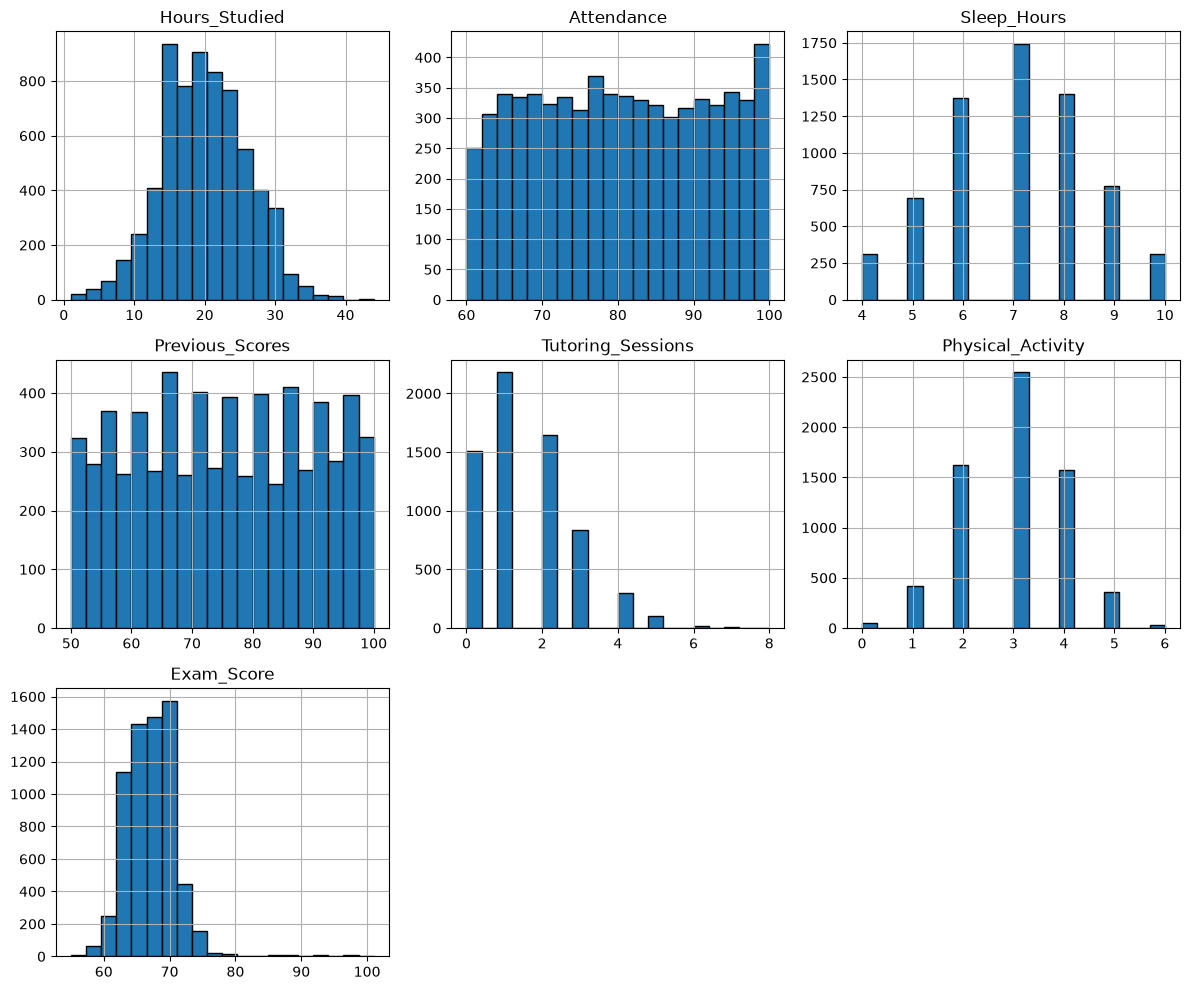

In [30]:
df.select_dtypes(include='number').hist(
    figsize=(12,10), 
    bins=20,
    edgecolor='black'
)

plt.tight_layout() 
plt.show()

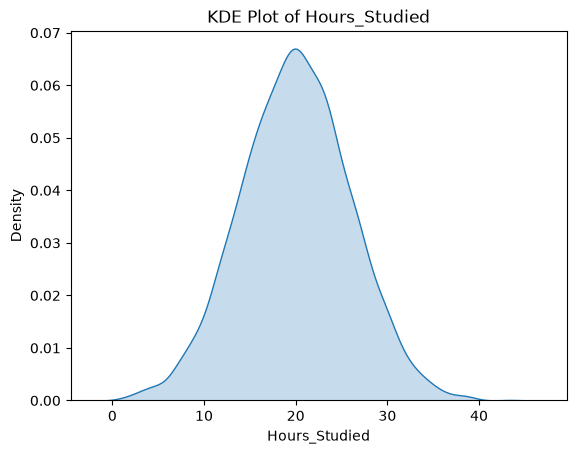

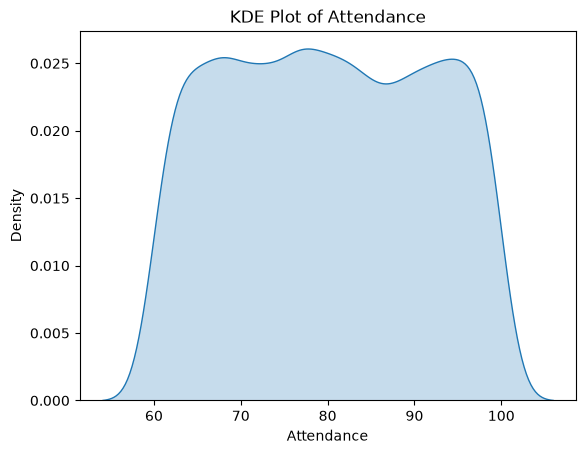

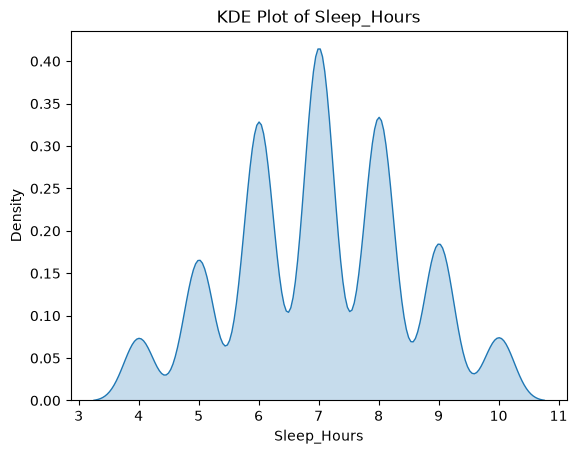

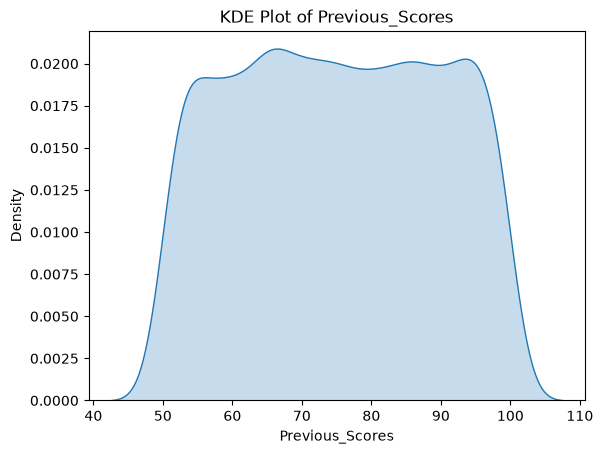

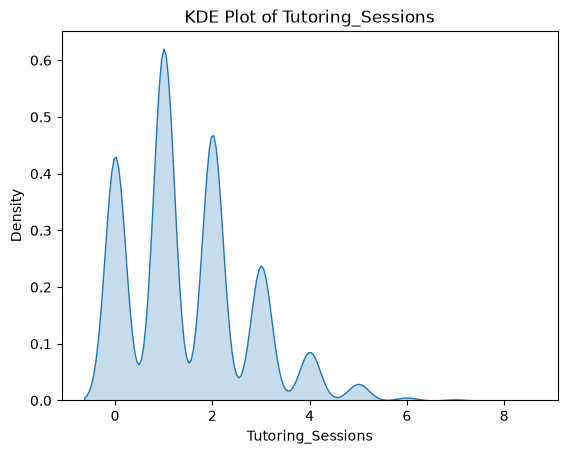

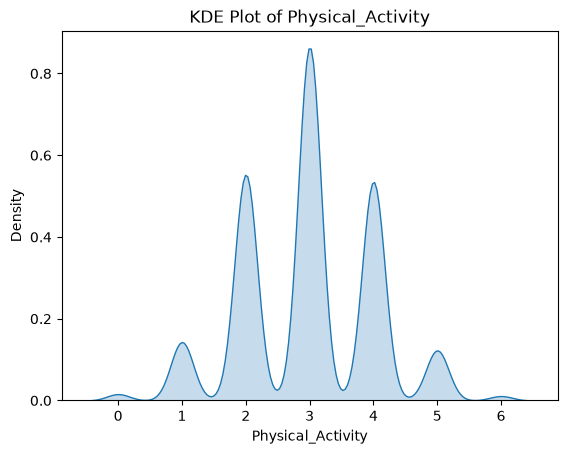

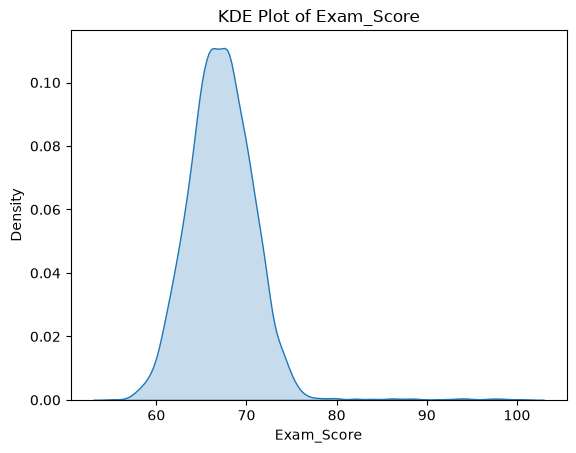

In [32]:
numeric_columns = df.select_dtypes(include='number').columns 

for col in numeric_columns: 
    sns.kdeplot(data=df,x=col,fill=True) 
    plt.title('KDE Plot of ' + col) 
    plt.show()

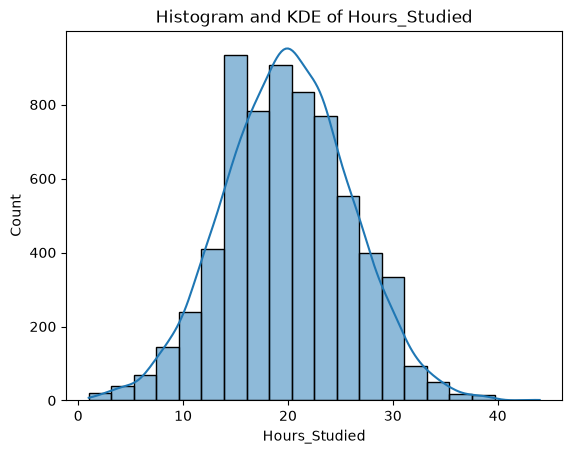

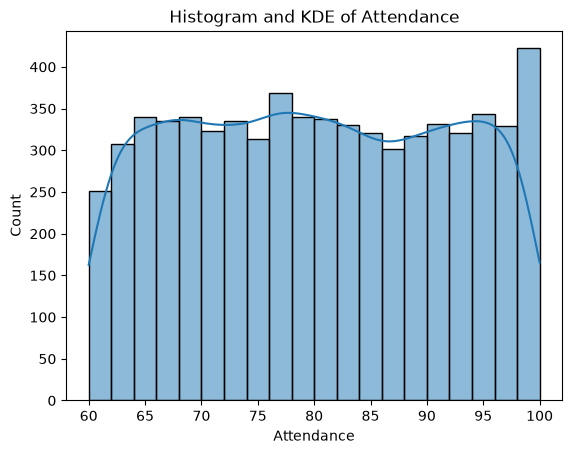

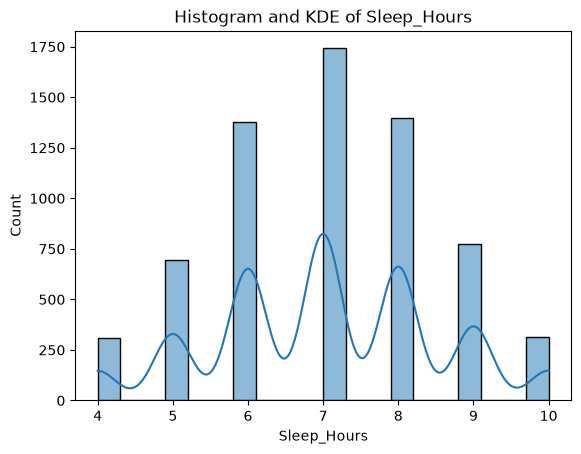

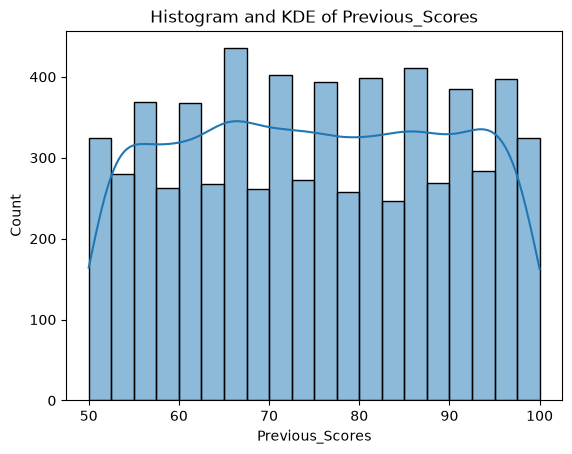

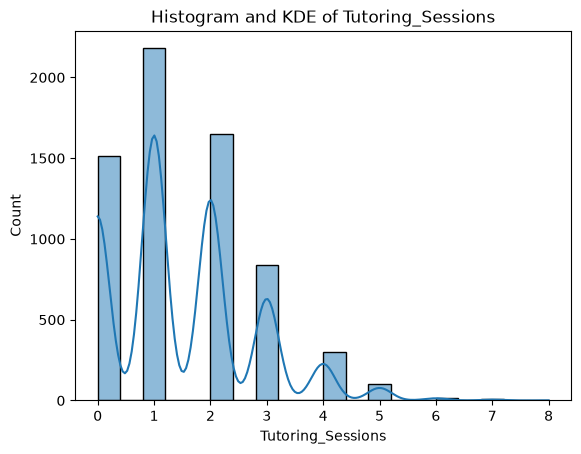

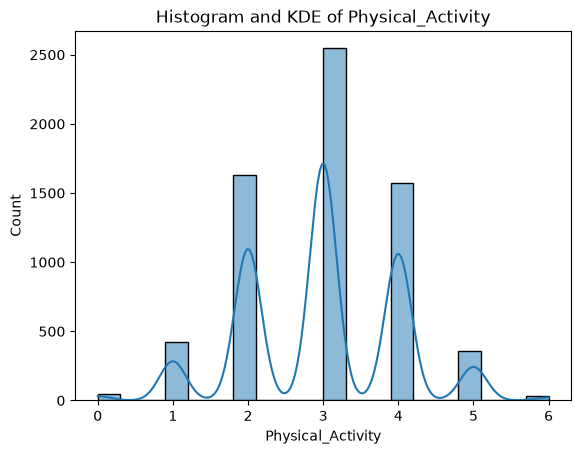

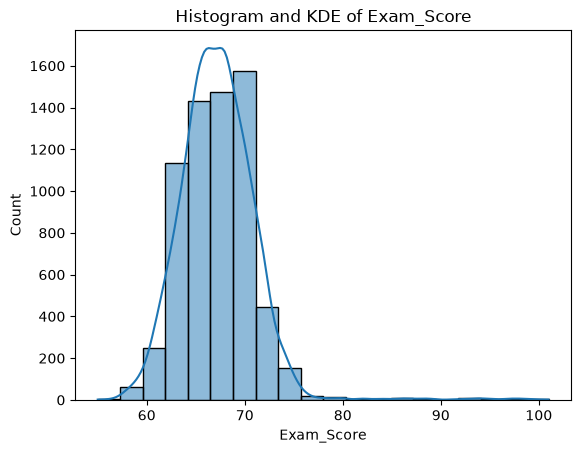

In [33]:
numeric_columns = df.select_dtypes(include='number').columns 

for col in numeric_columns: 
    sns.histplot(data=df,x=col,kde=True,bins=20) 
    plt.title('Histogram and KDE of ' +  col) 
    plt.show()

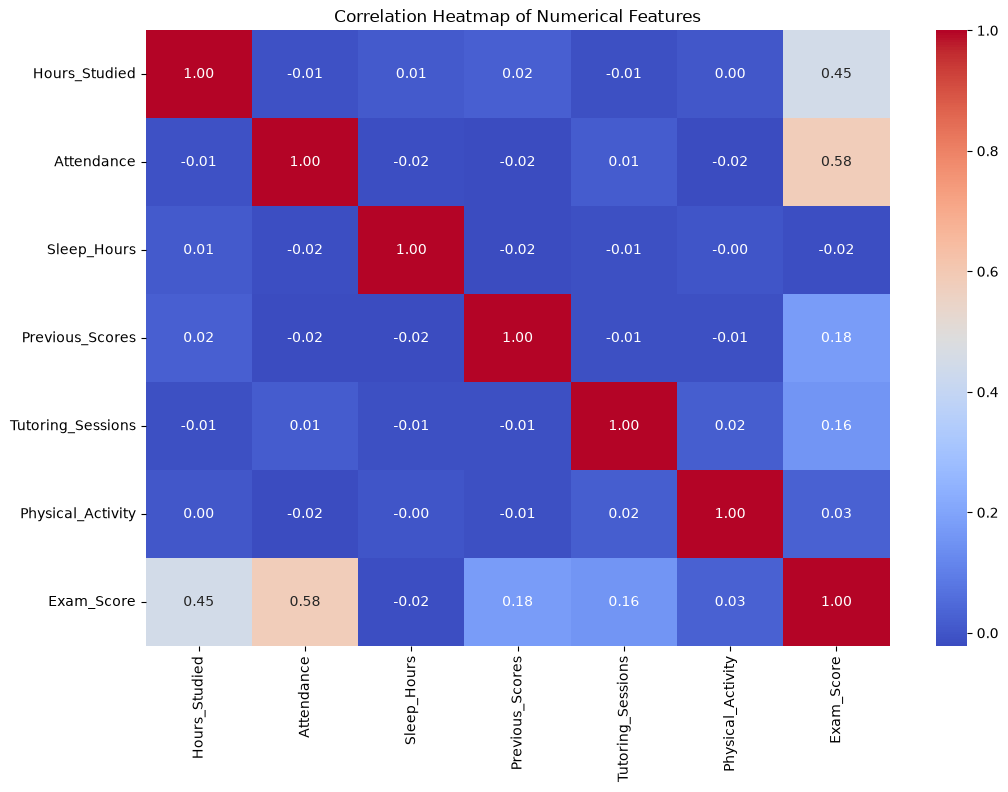

In [35]:
numeric_df = df.select_dtypes(include='number')

correlation = numeric_df.corr() 

plt.figure(figsize=(12,8)) 

sns.heatmap(correlation,annot=True,cmap='coolwarm',fmt='.2f') 

plt.title('Correlation Heatmap of Numerical Features') 
plt.show()

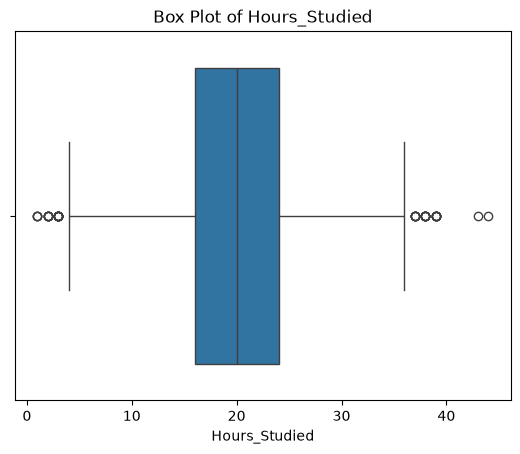

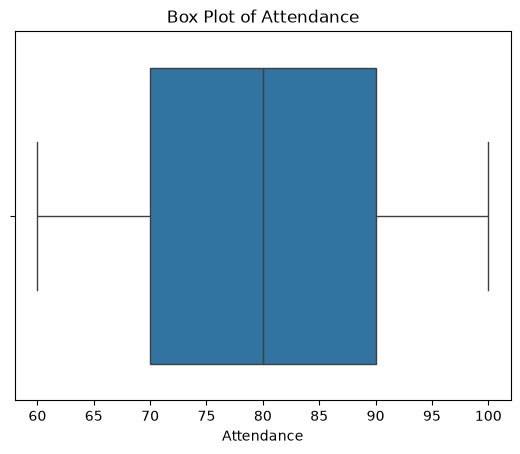

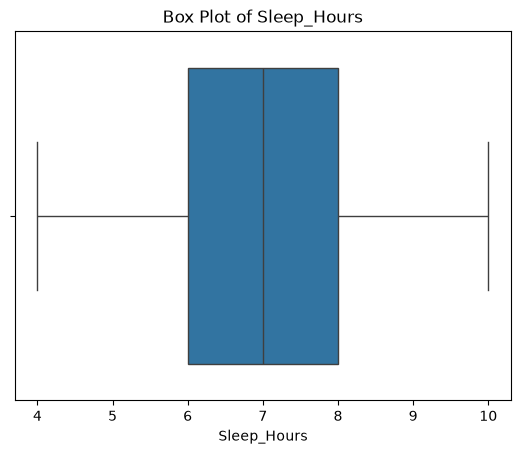

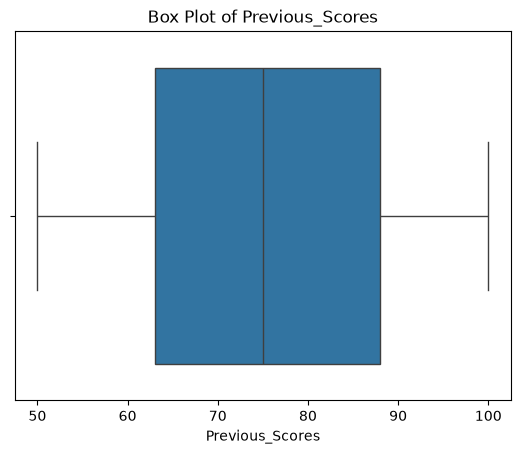

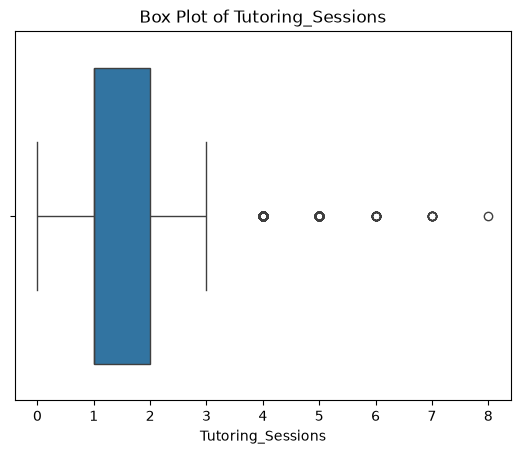

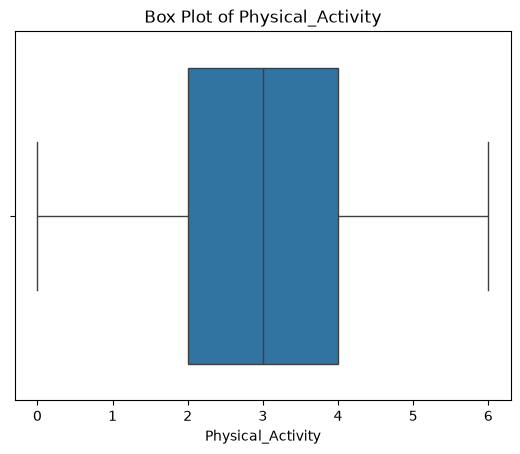

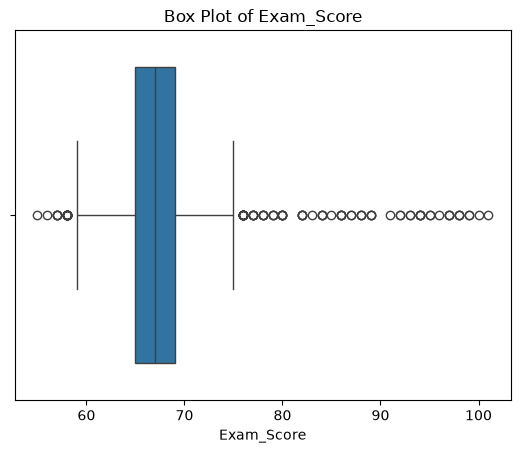

In [38]:
numeric_columns = df.select_dtypes(include='number').columns  

for col in numeric_columns: 
    sns.boxplot(x=df[col])
    plt.title('Box Plot of ' + col) 
    plt.show()


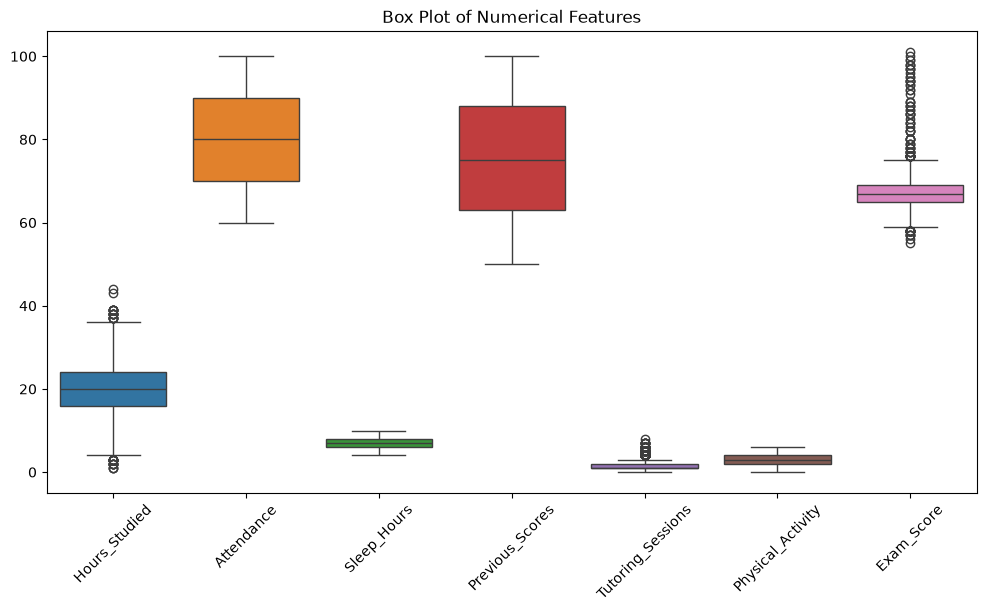

In [53]:
plt.figure(figsize=(12,6))

sns.boxplot(data=df.select_dtypes(include='number')) 

plt.xticks(rotation=45) 
plt.title('Box Plot of Numerical Features') 
plt.show()

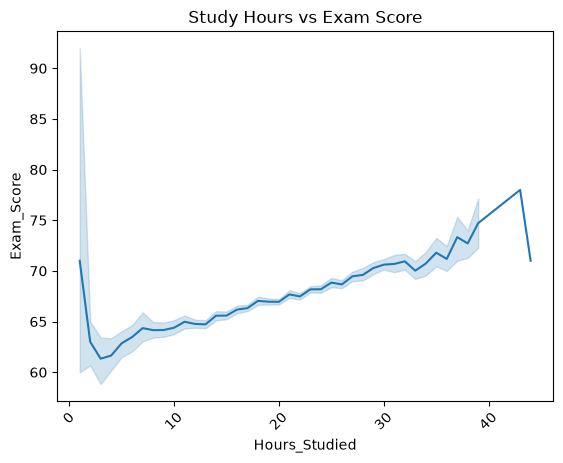

In [57]:
sns.lineplot(data=df,x='Study_Hours',y='Exam_Score') 

plt.title('Study Hours vs Exam Score')  
plt.xticks(rotation=45)
plt.show()             

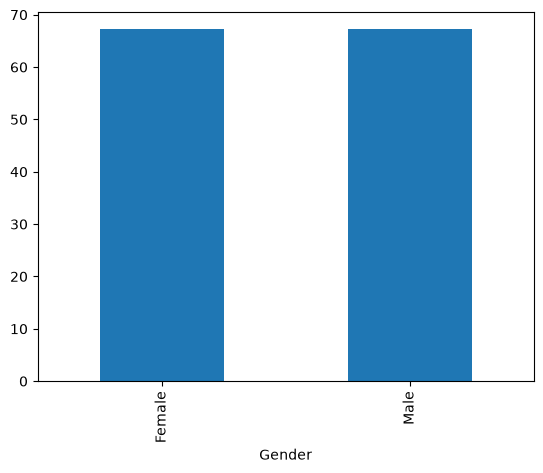

In [102]:
avg = df.groupby('Gender')['Exam_Score'].mean() 

avg.plot(kind='bar') 

plt.show()

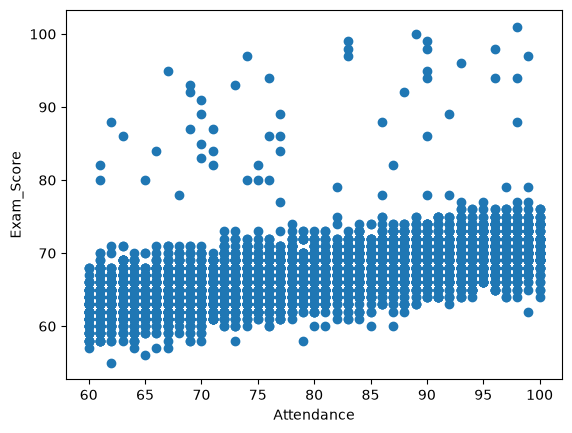

In [115]:
plt.scatter(df['Attendance'],df['Exam_Score']) 

plt.xlabel('Attendance') 
plt.ylabel('Exam_Score') 
plt.show()

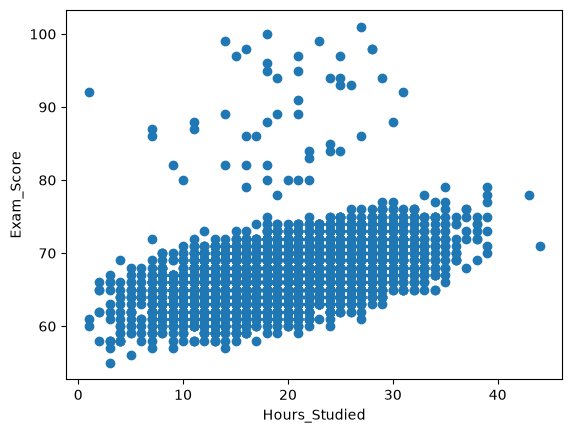

In [116]:
plt.scatter(df['Hours_Studied'],df['Exam_Score']) 

plt.xlabel('Hours_Studied') 
plt.ylabel('Exam_Score') 
plt.show()

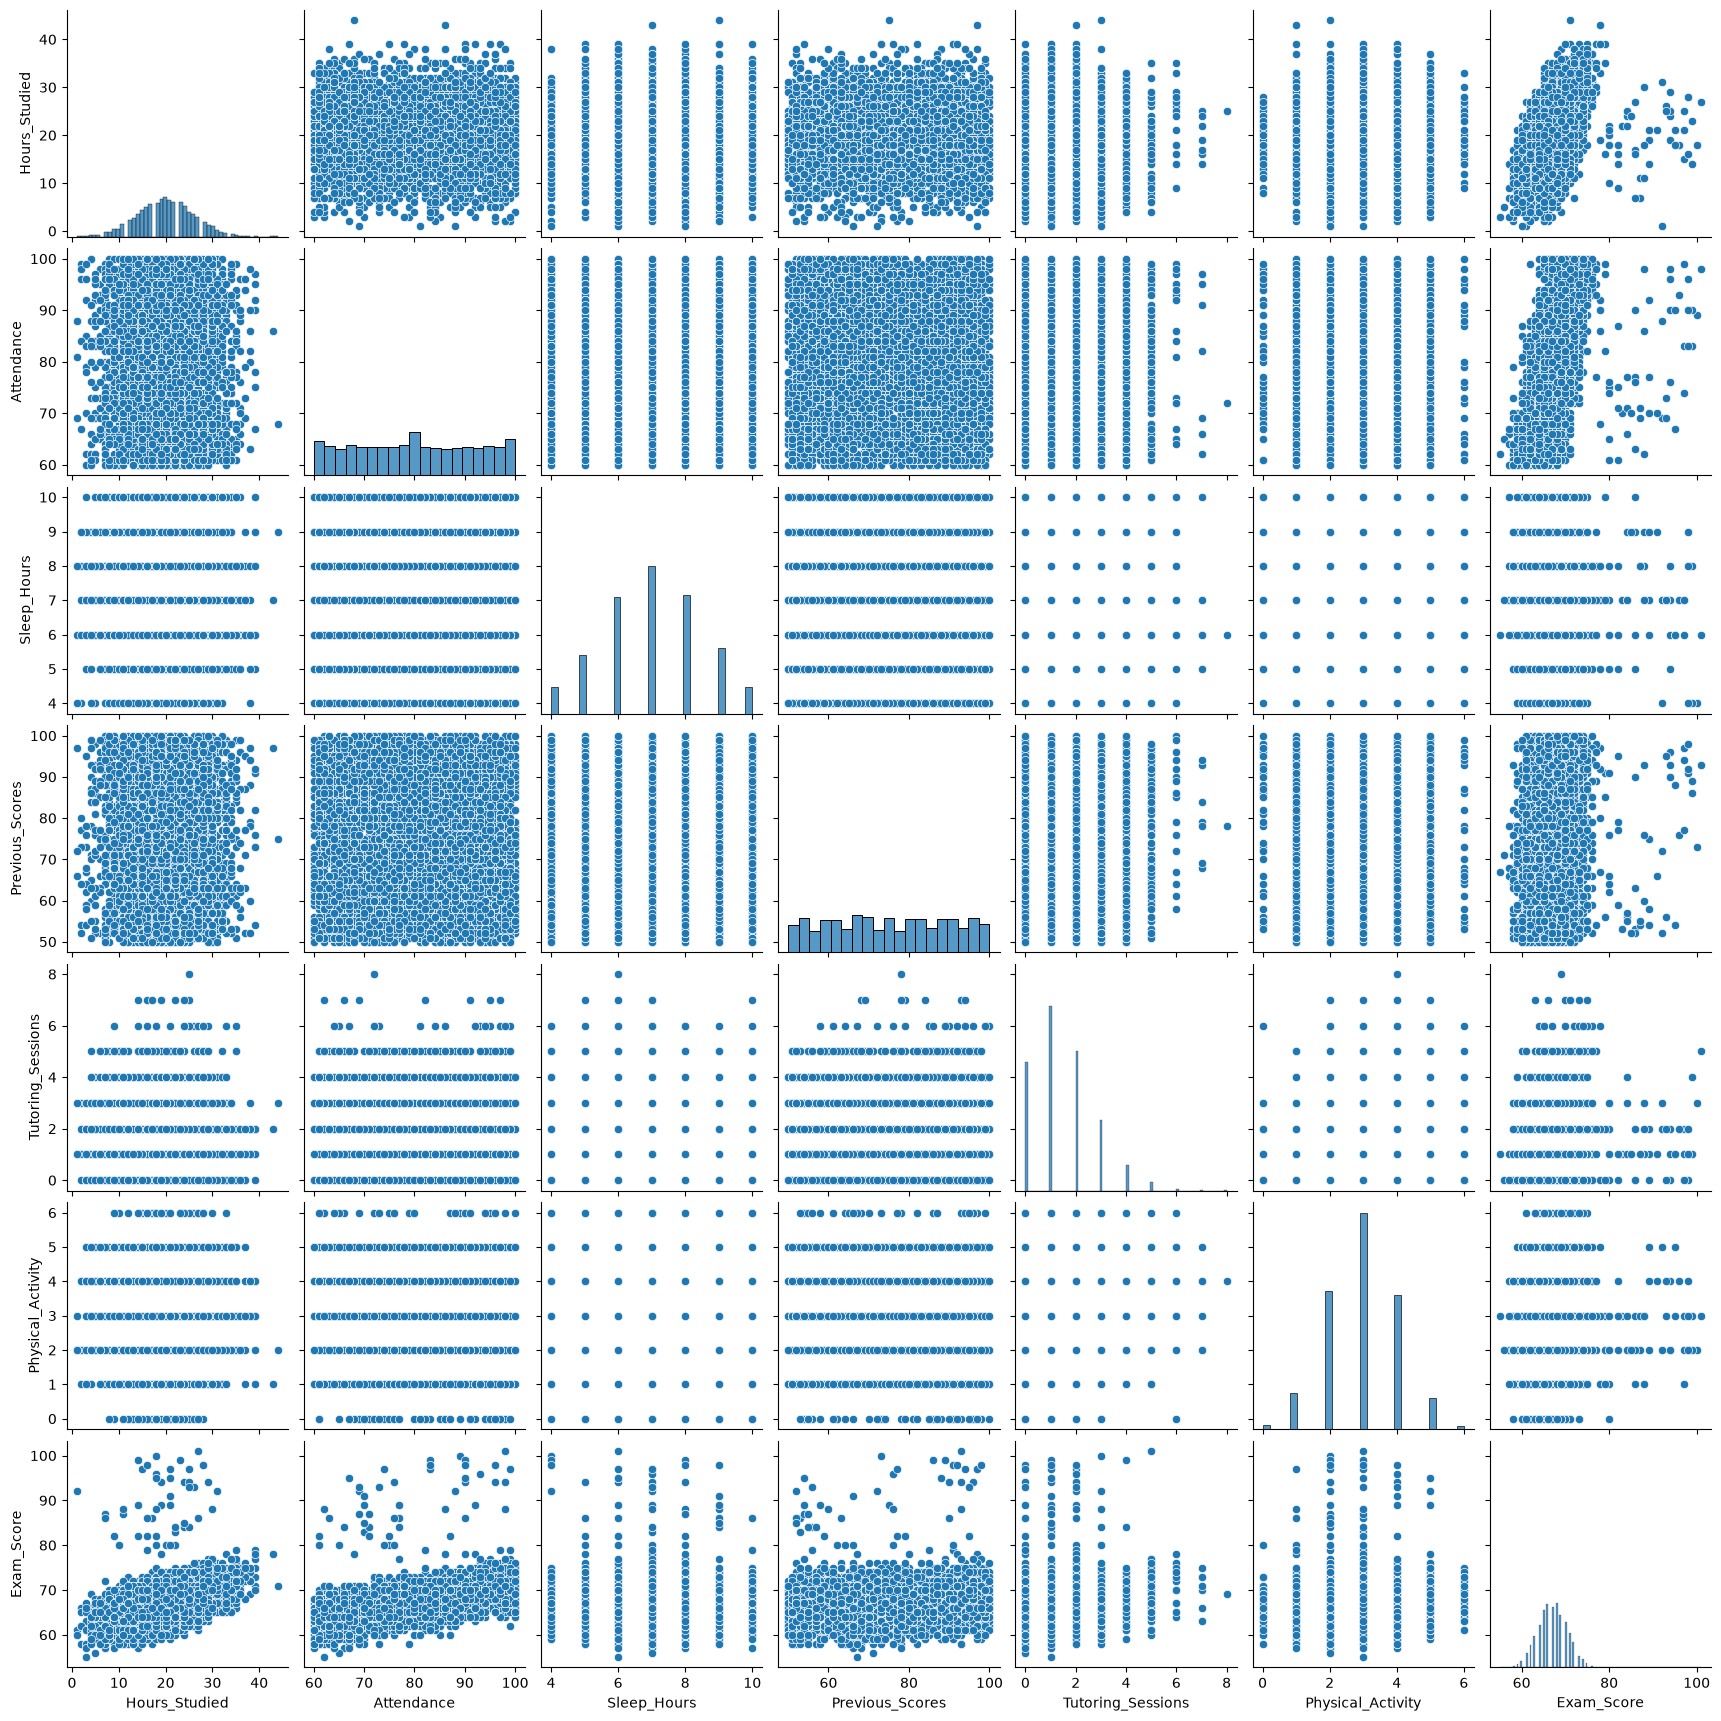

In [117]:
sns.pairplot(df) 
plt.show()

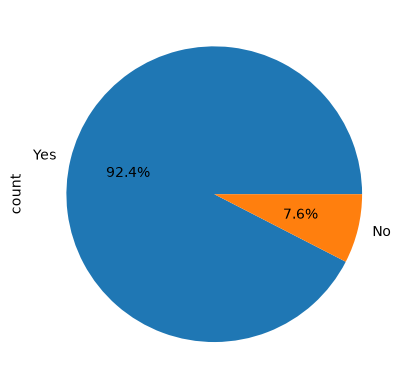

In [118]:
df['Internet_Access'].value_counts().plot.pie(autopct="%1.1f%%") 
plt.show()

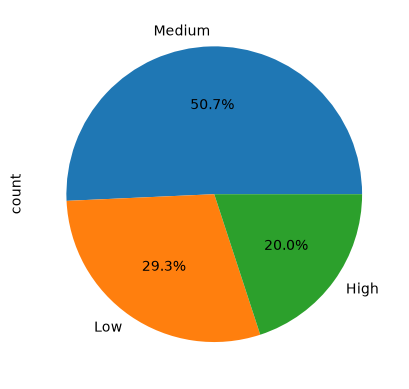

In [119]:
df['Motivation_Level'].value_counts().plot.pie(autopct="%1.1f%%") 
plt.show()

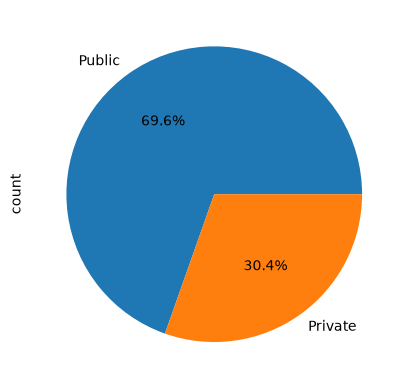

In [120]:
df['School_Type'].value_counts().plot.pie(autopct="%1.1f%%") 
plt.show()

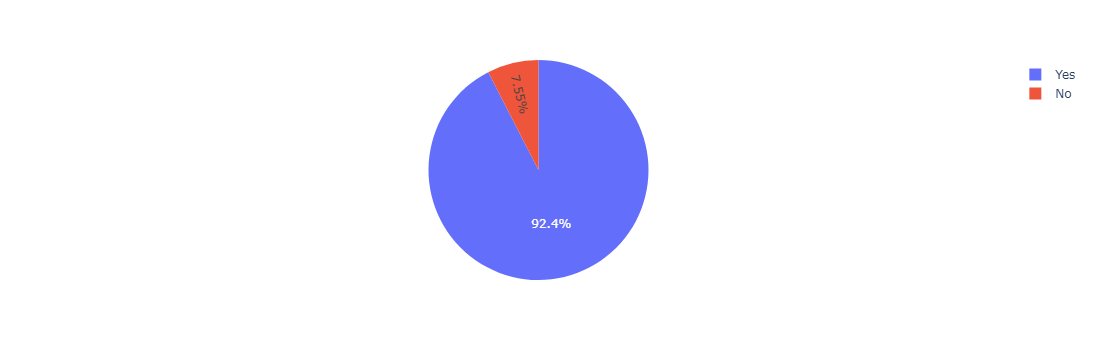

In [129]:
px.pie(df,names='Internet_Access').show()

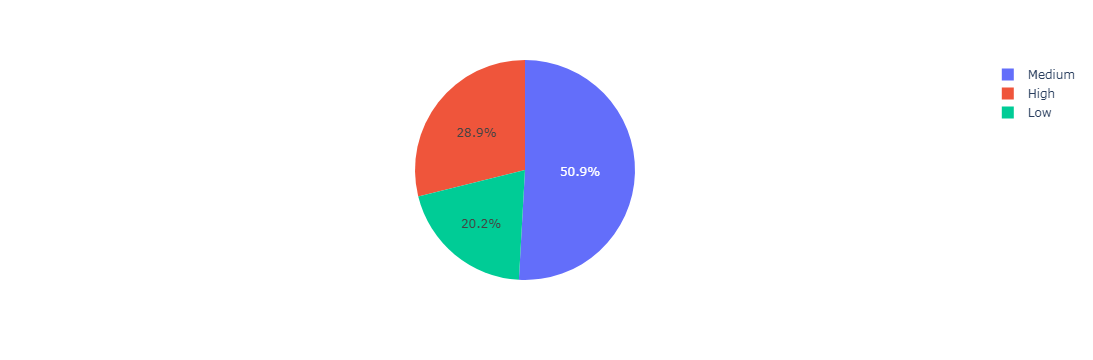

In [128]:
px.pie(df,names='Parental_Involvement').show()

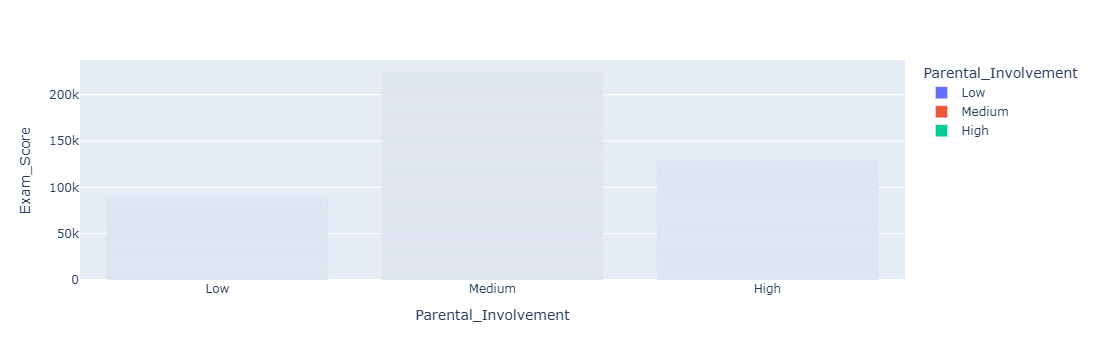

In [137]:
px.bar(df,x='Parental_Involvement',y='Exam_Score', 

color='Parental_Involvement').show()

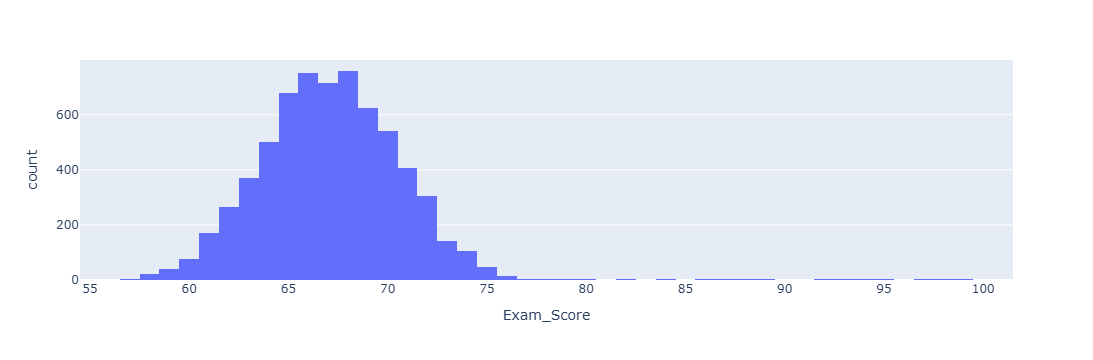

In [139]:
px.histogram(df,x='Exam_Score').show()

# Summary of Findings
1.Study Hours - Analyze the relationships betwwn hours studied and exam scores 2.Attendance - Examine attendance patterns and compare them with exam scores 3.Parental Involvement - Compare average score with parental involvement categories

# Conclusions and Business Recommendations 
1.Study Hours - Analyze whether students who study more achieve high exam scores 
2.Attendance - Analyze whether students with highest attendance tend to achieve high exam score 
3.Parental Involvement - Compare exam scores different with parental involvement levels 

Business Recommendations 
1.Study Hours - Schools can introduced personalized study schedules 
2.Attendance - Schools can monitor attendance 
3.Parental Involvement - Schools can organize parent-teacher meeting 

# Final Conclusion 
Exploratory Data Analysis helps schools understand factors associated with student performance
